In [ ]:
#EXP 9A – Stock Price Prediction Using Linear Regression

MSE: 6.517197331025271e-21
RMSE: 8.072916035129605e-11
R2 Score: 1.0


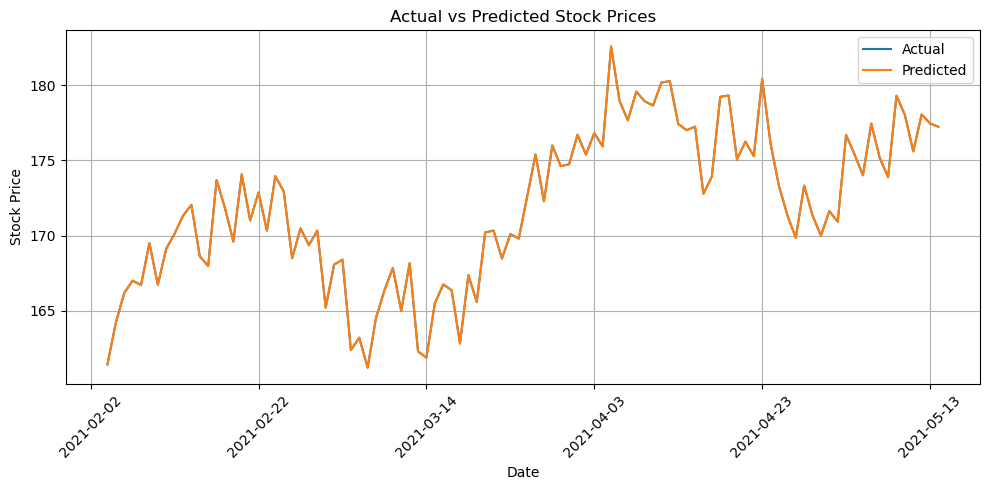

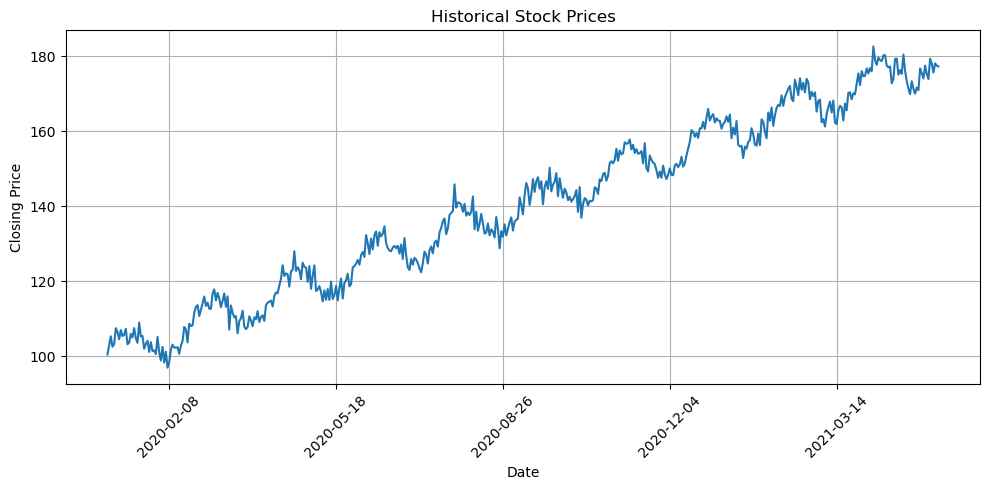

In [7]:
"""
AIM:
To predict stock prices using a Linear Regression model and compare the predicted values with actual stock prices.
PROCEDURE:
1. Import the required Python libraries.
2. Generate stock price data and create a DataFrame.
3. Preprocess the data and create features using previous closing prices.
4. Split the dataset into training and testing sets.
5. Train the Linear Regression model and predict stock prices.
6. Evaluate the model using MSE and \(R^2\) score.
7. Plot the actual and predicted stock prices.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Generate stock price dataset
np.random.seed(42)
dates = pd.date_range("2020-01-01", periods=500, freq="D")
trend = np.linspace(100, 180, 500)
seasonal = 5 * np.sin(np.linspace(0, 20*np.pi, 500))
close = trend + seasonal + np.random.normal(0, 2, 500)

df = pd.DataFrame({"Date": dates, "Close": close})
df["Open"] = df["Close"] + np.random.normal(0, 1, 500)
df["High"] = df[["Open", "Close"]].max(axis=1) + 2
df["Low"] = df[["Open", "Close"]].min(axis=1) - 2
df["Volume"] = np.random.randint(100000, 1000000, 500)
df["Days"] = np.arange(500)
df["Previous_Close"] = df["Close"].shift(1)
df.dropna(inplace=True)

# Select features and target
X = df[["Days", "Open", "High", "Low", "Previous_Close", "Volume"]]
y = df["Close"]

# Split data chronologically
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Train model and predict
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

# Evaluate model
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2 Score:", r2_score(y_test, pred))

# Plot actual vs predicted prices
plt.figure(figsize=(10, 5))
plt.plot(df["Date"].iloc[split:], y_test, label="Actual")
plt.plot(df["Date"].iloc[split:], pred, label="Predicted")
plt.title("Actual vs Predicted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(6))
plt.tight_layout()
plt.show()

# Plot historical stock prices
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["Close"])
plt.title("Historical Stock Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(6))
plt.tight_layout()
plt.show()

"""
RESULT:
The Linear Regression model was successfully trained to predict stock prices. 
The actual and predicted prices were visualized using graphs, and the model performance was evaluated using MSE and \(R^2\) score.
"""

In [ ]:
#EXP 9B – Time-Series Forecasting Using Linear Regression

MSE: 5447.163612684265
RMSE: 73.8049023621349
R2 Score: 0.10767914958065428


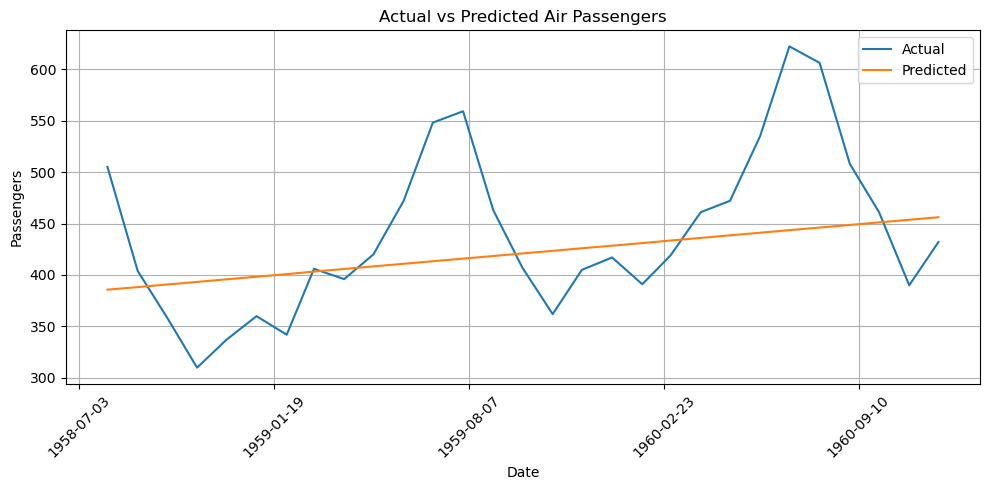

Next 12 Months Predictions: [458.62860412 461.14217628 463.65574844 466.1693206  468.68289276
 471.19646493 473.71003709 476.22360925 478.73718141 481.25075357
 483.76432573 486.27789789]


C:\Users\Zaara\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [6]:
"""
AIM:
To forecast airline passenger numbers using Linear Regression and visualize the actual and predicted values.
PROCEDURE:
1. Import the required libraries and load the airline passenger dataset.
2. Convert the date column into datetime format.
3. Create time-based features and split the data into training and testing sets.
4. Train the Linear Regression model.
5. Predict passenger numbers and evaluate the model.
6. Forecast passenger numbers for the next 12 months.
7. Plot the actual, predicted, and future passenger values.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Dataset
passengers = [
112,118,132,129,121,135,148,148,136,119,104,118,
115,126,141,135,125,149,170,170,158,133,114,140,
145,150,178,163,172,178,199,199,184,162,146,166,
171,180,193,181,183,218,230,242,209,191,172,194,
196,196,236,235,229,243,264,272,237,211,180,201,
204,188,235,227,234,264,302,293,259,229,203,229,
242,233,267,269,270,315,364,347,312,274,237,278,
284,277,317,313,318,374,413,405,355,306,271,306,
315,301,356,348,355,422,465,467,404,347,305,336,
340,318,362,348,363,435,491,505,404,359,310,337,
360,342,406,396,420,472,548,559,463,407,362,405,
417,391,419,461,472,535,622,606,508,461,390,432
]

dates = pd.date_range("1949-01-01", periods=len(passengers), freq="MS")
df = pd.DataFrame({"Date": dates, "Passengers": passengers})
df["Month_Number"] = np.arange(len(df))

# Split dataset chronologically
split = int(len(df) * 0.8)
X = df[["Month_Number"]]
y = df["Passengers"]

model = LinearRegression()
model.fit(X.iloc[:split], y.iloc[:split])
pred = model.predict(X.iloc[split:])

# Evaluation
print("MSE:", mean_squared_error(y.iloc[split:], pred))
print("RMSE:", np.sqrt(mean_squared_error(y.iloc[split:], pred)))
print("R2 Score:", r2_score(y.iloc[split:], pred))

# Actual vs Predicted graph
plt.figure(figsize=(10, 5))
plt.plot(df["Date"].iloc[split:], y.iloc[split:], label="Actual")
plt.plot(df["Date"].iloc[split:], pred, label="Predicted")
plt.title("Actual vs Predicted Air Passengers")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(6))
plt.tight_layout()
plt.show()

# Predict next 12 months
future = np.arange(len(df), len(df)+12).reshape(-1, 1)
print("Next 12 Months Predictions:", model.predict(future))

"""RESULT:
The Linear Regression model was successfully implemented for airline passenger forecasting.
The actual and predicted values were plotted, and passenger numbers for the next 12 months were estimated."""
